# 07 小兔鲜儿 - 用户模块


本篇根据配套讲义 `rabbit-shop/07-用户模块.md` 整理，承接 06 的登录与会员信息保存，完成会员展示、设置页退出登录、个人资料查询、头像上传与表单更新。

顺序：会员中心“我的” → 复用猜你喜欢分页 → 会员分包与预下载 → 设置页退出登录 → 个人信息展示 → 上传头像 → 收集并保存表单。

复用 01、06 的会员 Store 和请求拦截器，以及 02 的 `XtxGuess`。页面直接读取 Store 中的头像昵称，修改成功后同步更新 Store，其他页面才能看到新的会员信息。

资料来自[课程网盘](https://pan.baidu.com/s/1uhQQvqs9ESRvhEvgzgSUWQ?pwd=9988)，提取码 `9988`，配套包为 `02-笔记.rar`。五张教学图片直接内嵌在本篇 Notebook 中。

| 文件 | 本篇职责 |
| --- | --- |
| `src/pages/my/my.vue` | 会员展示、订单入口、猜你喜欢分页 |
| `src/composables/index.ts` | 复用猜你喜欢的组件引用与触底事件 |
| `src/pagesMember/settings/settings.vue` | 设置项、退出确认与登录状态切换 |
| `src/pagesMember/profile/profile.vue` | 头像上传、资料表单与保存 |
| `src/services/profile.ts` | 查询、修改会员资料 |
| `src/types/member.d.ts` | 会员详情、性别、修改请求类型 |
| `src/pages.json` | 会员分包、页面路由、预下载 |

原稿以分步骤片段展开。本篇保留完整静态结构和各项动态改造，说明片段需要怎样合并。


## 会员中心页（我的）

会员中心主要完成两项业务：

1. 从会员 Store 取得当前头像、昵称，区分已登录与未登录。
2. 展示猜你喜欢，在页面滚动触底时加载下一页，把复用逻辑封装为组合式函数。

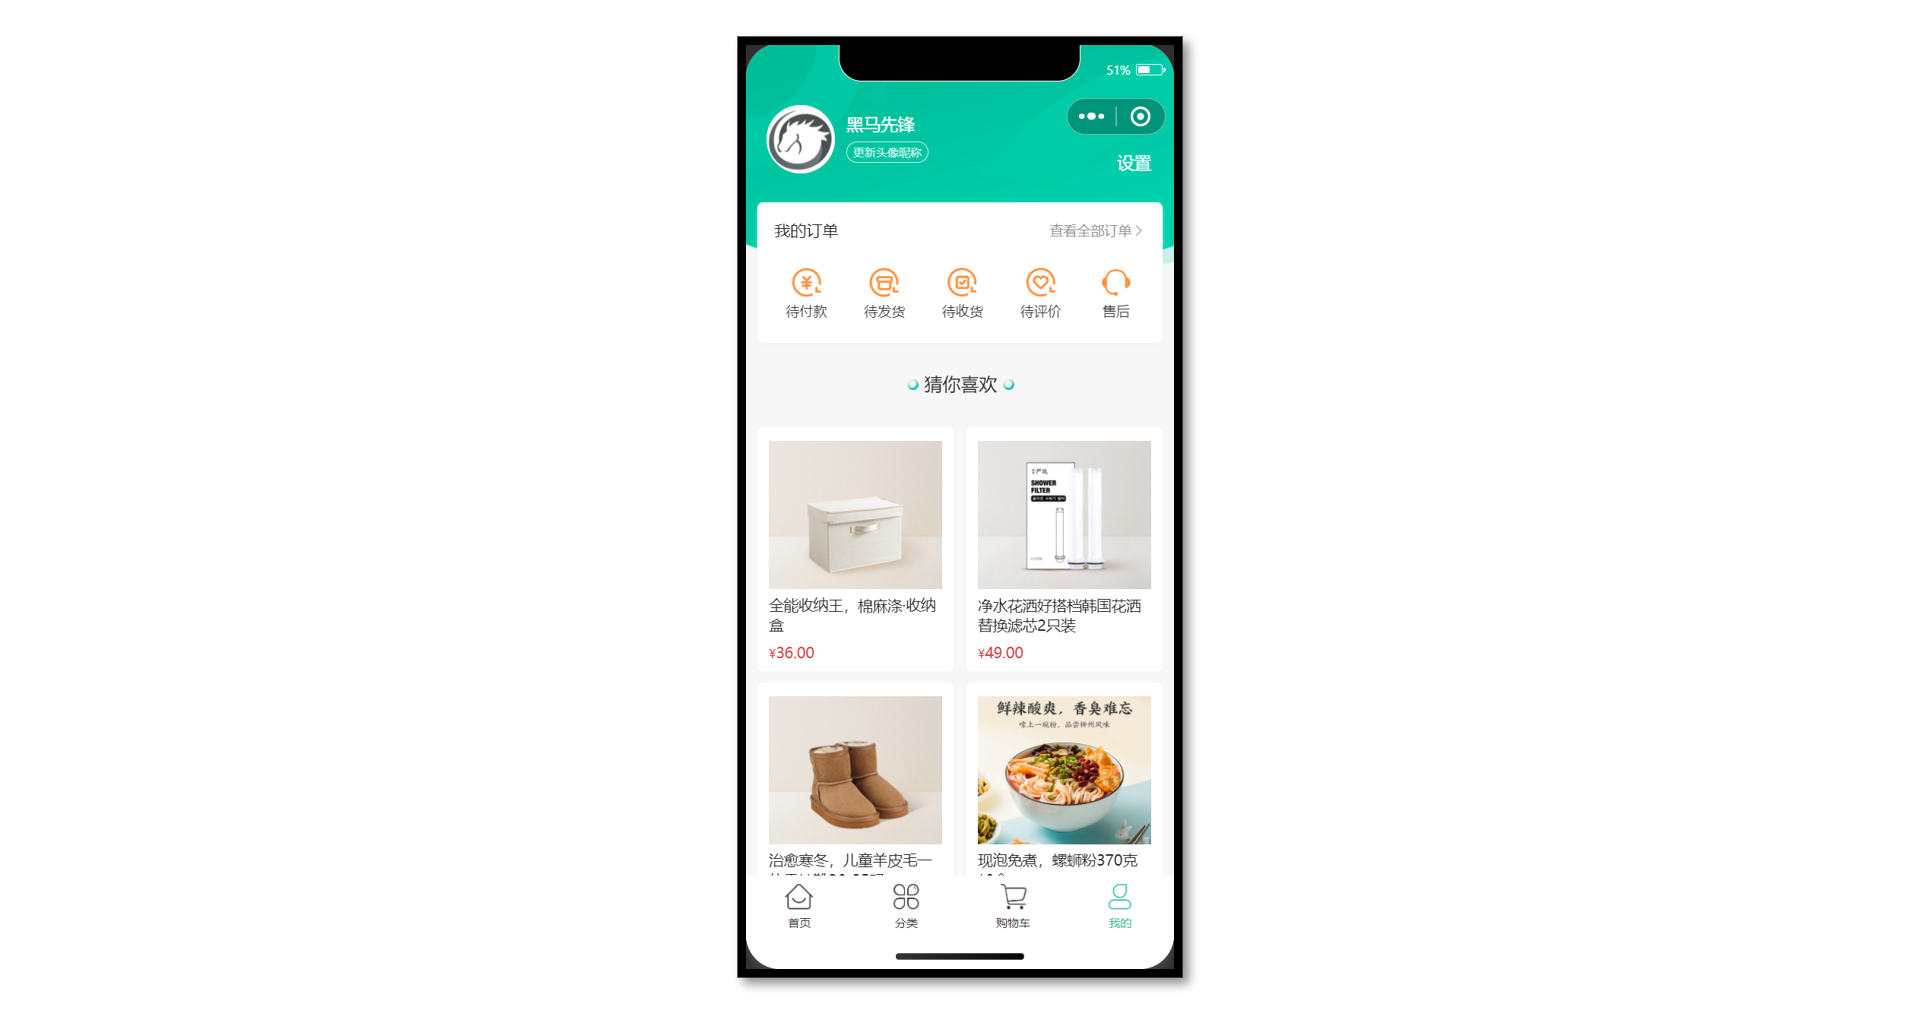


### 准备会员中心静态结构

替换 `src/pages/my/my.vue` 的练习代码，先准备原课页面和完整 SCSS：


```vue
<!-- src/pages/my/my.vue -->

<script setup lang="ts">
// 获取屏幕边界到安全区域距离
const { safeAreaInsets } = uni.getSystemInfoSync()
// 订单选项
const orderTypes = [
  { type: 1, text: '待付款', icon: 'icon-currency' },
  { type: 2, text: '待发货', icon: 'icon-gift' },
  { type: 3, text: '待收货', icon: 'icon-check' },
  { type: 4, text: '待评价', icon: 'icon-comment' },
]
</script>

<template>
  <scroll-view class="viewport" scroll-y enable-back-to-top>
    <!-- 个人资料 -->
    <view class="profile" :style="{ paddingTop: safeAreaInsets!.top + 'px' }">
      <!-- 情况1：已登录 -->
      <view class="overview" v-if="false">
        <navigator url="/pagesMember/profile/profile" hover-class="none">
          <image
            class="avatar"
            mode="aspectFill"
            src="https://pcapi-xiaotuxian-front-devtest.itheima.net/miniapp/uploads/avatar_3.jpg"
          ></image>
        </navigator>
        <view class="meta">
          <view class="nickname"> 黑马程序员 </view>
          <navigator class="extra" url="/pagesMember/profile/profile" hover-class="none">
            <text class="update">更新头像昵称</text>
          </navigator>
        </view>
      </view>
      <!-- 情况2：未登录 -->
      <view class="overview" v-else>
        <navigator url="/pages/login/login" hover-class="none">
          <image
            class="avatar gray"
            mode="aspectFill"
            src="http://yjy-xiaotuxian-dev.oss-cn-beijing.aliyuncs.com/picture/2021-04-06/db628d42-88a7-46e7-abb8-659448c33081.png"
          ></image>
        </navigator>
        <view class="meta">
          <navigator url="/pages/login/login" hover-class="none" class="nickname">
            未登录
          </navigator>
          <view class="extra">
            <text class="tips">点击登录账号</text>
          </view>
        </view>
      </view>
      <navigator class="settings" url="/pagesMember/settings/settings" hover-class="none">
        设置
      </navigator>
    </view>
    <!-- 我的订单 -->
    <view class="orders">
      <view class="title">
        我的订单
        <navigator class="navigator" url="/pagesOrder/list/list?type=0" hover-class="none">
          查看全部订单<text class="icon-right"></text>
        </navigator>
      </view>
      <view class="section">
        <!-- 订单 -->
        <navigator
          v-for="item in orderTypes"
          :key="item.type"
          :class="item.icon"
          :url="`/pagesOrder/list/list?type=${item.type}`"
          class="navigator"
          hover-class="none"
        >
          {{ item.text }}
        </navigator>
        <!-- 客服 -->
        <button class="contact icon-handset" open-type="contact">售后</button>
      </view>
    </view>
    <!-- 猜你喜欢 -->
    <view class="guess">
      <XtxGuess ref="guessRef" />
    </view>
  </scroll-view>
</template>

<style lang="scss">
page {
  height: 100%;
  overflow: hidden;
  background-color: #f7f7f8;
}

.viewport {
  height: 100%;
  background-repeat: no-repeat;
  background-image: url(https://pcapi-xiaotuxian-front-devtest.itheima.net/miniapp/images/center_bg.png);
  background-size: 100% auto;
}

/* 用户信息 */
.profile {
  margin-top: 20rpx;
  position: relative;

  .overview {
    display: flex;
    height: 120rpx;
    padding: 0 36rpx;
    color: #fff;
  }

  .avatar {
    width: 120rpx;
    height: 120rpx;
    border-radius: 50%;
    background-color: #eee;
  }

  .gray {
    filter: grayscale(100%);
  }

  .meta {
    display: flex;
    flex-direction: column;
    justify-content: center;
    align-items: flex-start;
    line-height: 30rpx;
    padding: 16rpx 0;
    margin-left: 20rpx;
  }

  .nickname {
    max-width: 350rpx;
    margin-bottom: 16rpx;
    font-size: 30rpx;

    overflow: hidden;
    text-overflow: ellipsis;
    white-space: nowrap;
  }

  .extra {
    display: flex;
    font-size: 20rpx;
  }

  .tips {
    font-size: 22rpx;
  }

  .update {
    padding: 3rpx 10rpx 1rpx;
    color: rgba(255, 255, 255, 0.8);
    border: 1rpx solid rgba(255, 255, 255, 0.8);
    margin-right: 10rpx;
    border-radius: 30rpx;
  }

  .settings {
    position: absolute;
    bottom: 0;
    right: 40rpx;
    font-size: 30rpx;
    color: #fff;
  }
}

/* 我的订单 */
.orders {
  position: relative;
  z-index: 99;
  padding: 30rpx;
  margin: 50rpx 20rpx 0;
  background-color: #fff;
  border-radius: 10rpx;
  box-shadow: 0 4rpx 6rpx rgba(240, 240, 240, 0.6);

  .title {
    height: 40rpx;
    line-height: 40rpx;
    font-size: 28rpx;
    color: #1e1e1e;

    .navigator {
      font-size: 24rpx;
      color: #939393;
      float: right;
    }
  }

  .section {
    width: 100%;
    display: flex;
    justify-content: space-between;
    padding: 40rpx 20rpx 10rpx;
    .navigator,
    .contact {
      text-align: center;
      font-size: 24rpx;
      color: #333;
      &::before {
        display: block;
        font-size: 60rpx;
        color: #ff9545;
      }
    }
    .contact {
      padding: 0;
      margin: 0;
      border: 0;
      background-color: transparent;
      line-height: inherit;
    }
  }
}

/* 猜你喜欢 */
.guess {
  background-color: #f7f7f8;
  margin-top: 20rpx;
}
</style>
```

静态阶段用 `v-if="false"` 固定展示未登录状态，后面改为读取 Store。订单选项通过 `orderTypes` 生成不同状态入口，订单页面在后续订单模块实现。

头像区域通过 `safeAreaInsets.top` 适配顶部安全区，使用 px 单位。原稿的 `!` 是非空断言；在可能缺少安全区数据的平台，可以采用前面笔记介绍的缺值回退。

`XtxGuess` 延续全局自动导入。这里虽然写了 `ref="guessRef"`，脚本中的引用和触底事件还需要下一步补齐。


### 封装猜你喜欢组合式函数

在 `src/composables/index.ts` 中创建 `useGuessList`：


```typescript
// src/composables/index.ts

import type { XtxGuessInstance } from '@/types/components'
import { ref } from 'vue'

/**
 * 猜你喜欢组合式函数
 */
export const useGuessList = () => {
  // 获取猜你喜欢组件实例
  const guessRef = ref<XtxGuessInstance>()

  // 滚动触底事件
  const onScrolltolower = () => {
    guessRef.value?.getMore()
  }

  // 返回 ref 和事件处理函数
  return { guessRef, onScrolltolower }
}
```

组合式函数把“创建组件引用 → 触底时调用公开方法 → 返回引用与事件函数”封装起来。商品列表和分页状态仍然由 `XtxGuess` 管理，这个函数只连接页面滚动与组件方法。

每个页面调用一次 `useGuessList()`，会得到各自的 `guessRef`。不同页面不会因为复用了同一个函数而共享同一份组件引用。

首页也可以用它替换 02 中相同的触底逻辑；涉及首页下拉刷新时，仍保留原来的重置、重新加载步骤。


### 展示会员并连接分页

将静态会员区域改为读取 Store，给滚动容器绑定触底事件。原稿省略了组合式函数的导入，这里补齐：


```vue
<!-- src/pages/my/my.vue -->

<script setup lang="ts">
import { useMemberStore } from '@/stores'
import { useGuessList } from '@/composables'

// 获取会员信息
const memberStore = useMemberStore()

// 猜你喜欢组合式函数
const { guessRef, onScrolltolower } = useGuessList()
</script>

<template>
  <scroll-view class="viewport" scroll-y enable-back-to-top @scrolltolower="onScrolltolower">
    <!-- 个人资料 -->
    <view class="profile" :style="{ paddingTop: safeAreaInsets!.top + 'px' }">
      <!-- 情况1：已登录 -->
      <view class="overview" v-if="memberStore.profile">
        <navigator url="/pagesMember/profile/profile" hover-class="none">
          <image class="avatar" :src="memberStore.profile.avatar" mode="aspectFill"></image>
        </navigator>
        <view class="meta">
          <view class="nickname">
            {{ memberStore.profile.nickname || memberStore.profile.account }}
          </view>
          <navigator class="extra" url="/pagesMember/profile/profile" hover-class="none">
            <text class="update">更新头像昵称</text>
          </navigator>
        </view>
      </view>
      <!-- 情况2：未登录 -->
      <view class="overview" v-else> ...省略 </view>
    </view>
    <!-- 猜你喜欢 -->
    <view class="guess">
      <XtxGuess ref="guessRef" />
    </view>
  </scroll-view>
</template>
```

这是动态改造片段，合并时保留静态阶段的 `safeAreaInsets`、`orderTypes`、未登录区域、设置入口、订单区域和完整 SCSS。

`v-if="memberStore.profile"` 区分登录状态。昵称为空时使用 `account` 作为展示回退；头像直接绑定 `memberStore.profile.avatar`。登录、退出或后续修改 Store 后，这些绑定会跟着更新。

`@scrolltolower` 调用组合式函数返回的方法，进而调用 02 已通过 `defineExpose` 公开的 `getMore`。

**跟做检查**：登录后“我的”展示对应头像昵称；未登录时提供登录入口；滚动到猜你喜欢底部能够追加下一页。


## 会员设置页

会员的设置、个人信息等二级页面放进 `pagesMember` 分包：

- 按业务模块管理页面，便于维护。
- 减少主包体积，用到会员分包时再加载。

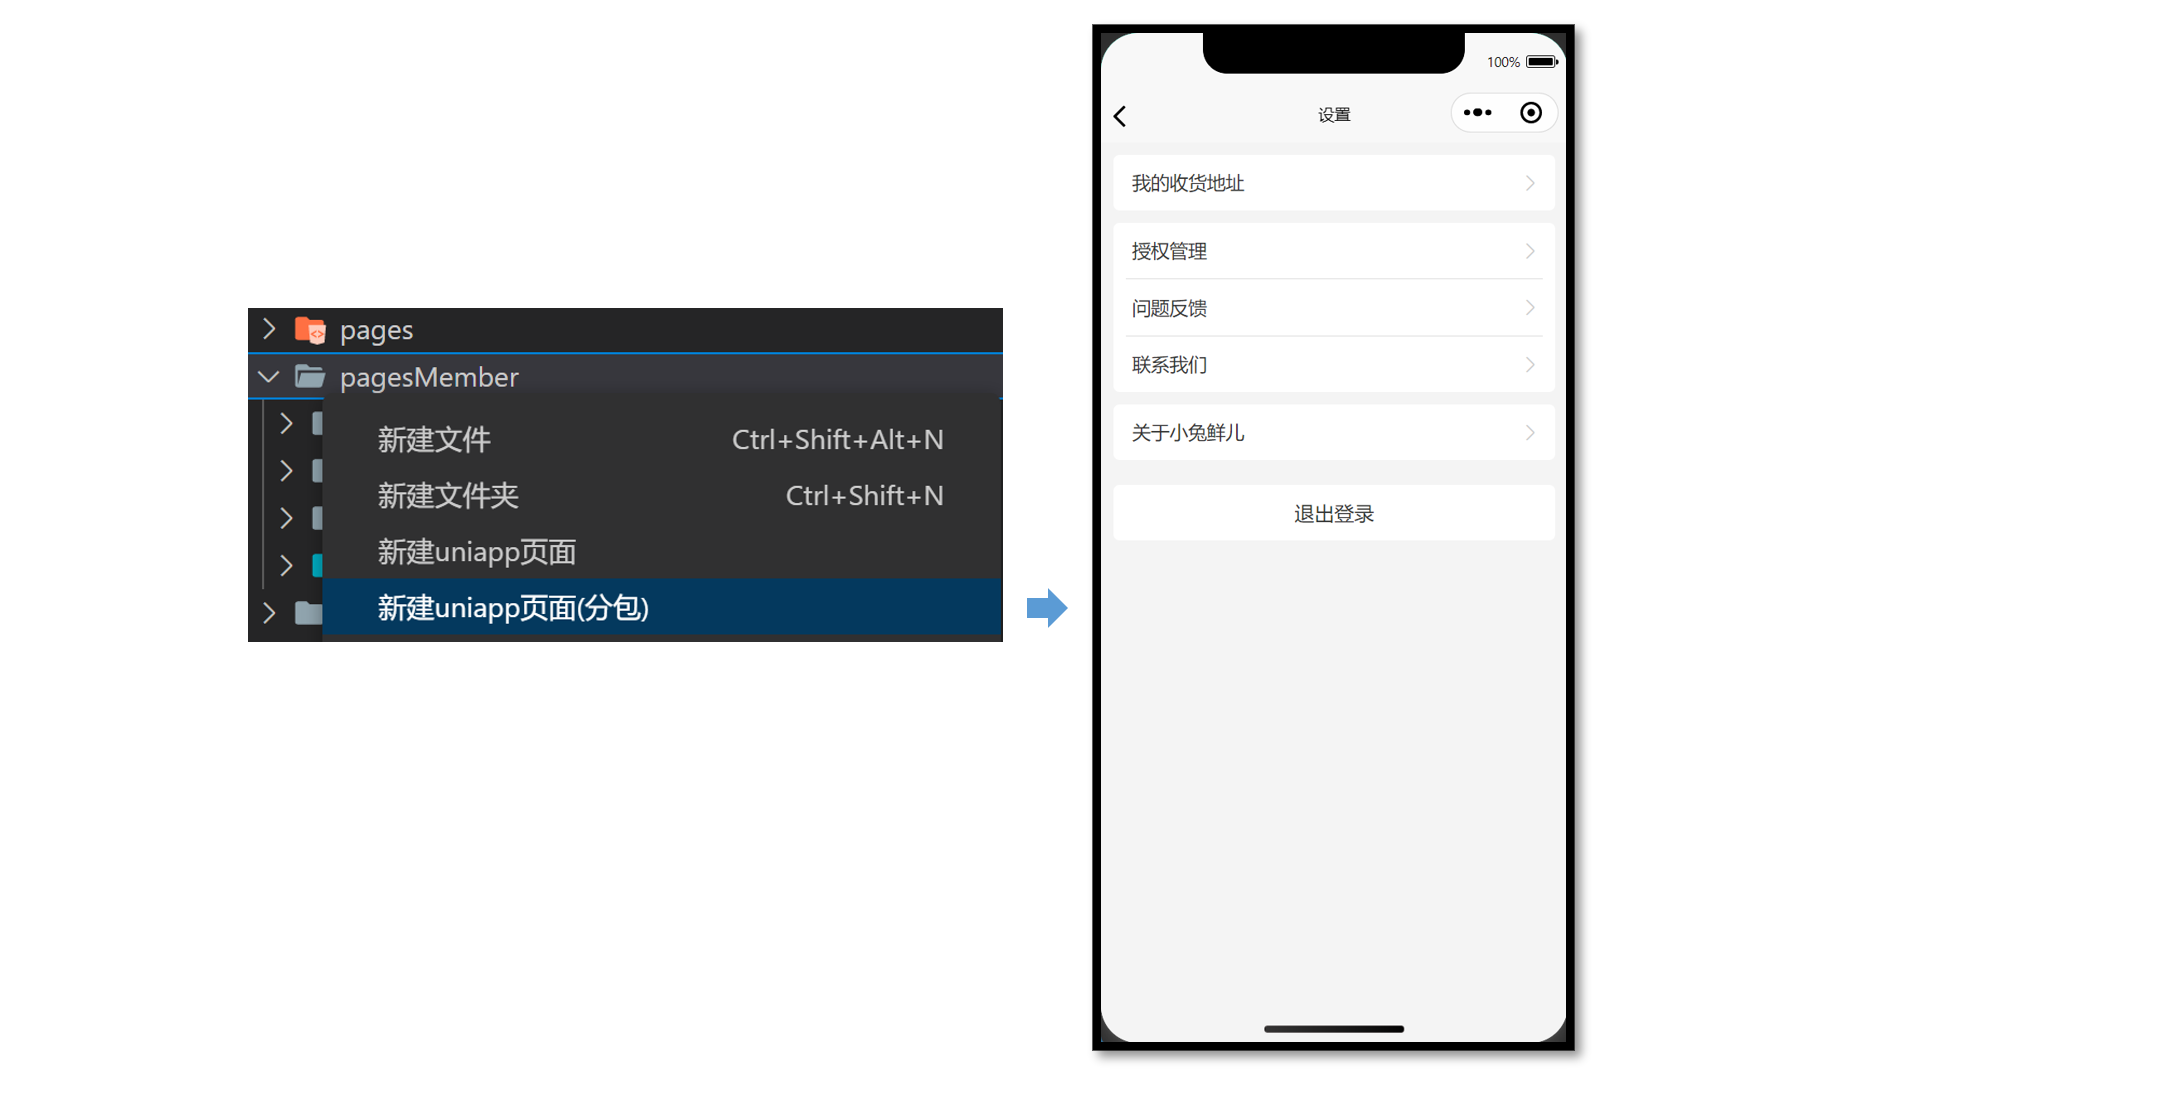


### 创建分包并配置预下载

原课使用 [uni-create-view](https://marketplace.visualstudio.com/items?itemName=mrmaoddxxaa.create-uniapp-view) 插件快速创建分包页面并注册路由。设置页路径为 `src/pagesMember/settings/settings.vue`。

在 `src/pages.json` 合并会员分包与预下载规则：


```jsonc
// src/pages.json

{
  // ...省略
  // 分包加载规则
  "subPackages": [
    {
      // 子包的根目录
      "root": "pagesMember",
      // 页面路径和窗口表现
      "pages": [
        {
          "path": "settings/settings",
          "style": {
            "navigationBarTitleText": "设置"
          }
        }
      ]
    }
  ],
  // 分包预下载规则
  "preloadRule": {
    "pages/my/my": {
      "network": "all",
      "packages": ["pagesMember"]
    }
  }
}
```

`root: "pagesMember"` 指定分包根目录；分包内的 `path` 相对根目录填写，因此设置页完整路由为 `/pagesMember/settings/settings`。

`preloadRule` 的 key 为触发预下载的主包页面 `pages/my/my`。进入“我的”时预下载会员分包；`network: "all"` 表示按原课配置不限制为 Wi-Fi。预下载准备代码，不会自动打开会员页面或请求会员资料。

这些配置合并到已有文件中，保留主包页面、tabBar 和其他分包。


### 设置页静态结构

在 `src/pagesMember/settings/settings.vue` 中准备：


```vue
<script setup lang="ts">
//
</script>

<template>
  <view class="viewport">
    <!-- 列表1 -->
    <view class="list" v-if="true">
      <navigator url="/pagesMember/address/address" hover-class="none" class="item arrow">
        我的收货地址
      </navigator>
    </view>
    <!-- 列表2 -->
    <view class="list">
      <button hover-class="none" class="item arrow" open-type="openSetting">授权管理</button>
      <button hover-class="none" class="item arrow" open-type="feedback">问题反馈</button>
      <button hover-class="none" class="item arrow" open-type="contact">联系我们</button>
    </view>
    <!-- 列表3 -->
    <view class="list">
      <navigator hover-class="none" class="item arrow" url=" ">关于小兔鲜儿</navigator>
    </view>
    <!-- 操作按钮 -->
    <view class="action">
      <view class="button">退出登录</view>
    </view>
  </view>
</template>

<style lang="scss">
page {
  background-color: #f4f4f4;
}

.viewport {
  padding: 20rpx;
}

/* 列表 */
.list {
  padding: 0 20rpx;
  background-color: #fff;
  margin-bottom: 20rpx;
  border-radius: 10rpx;
  .item {
    line-height: 90rpx;
    padding-left: 10rpx;
    font-size: 30rpx;
    color: #333;
    border-top: 1rpx solid #ddd;
    position: relative;
    text-align: left;
    border-radius: 0;
    background-color: #fff;
    &::after {
      width: auto;
      height: auto;
      left: auto;
      border: none;
    }
    &:first-child {
      border: none;
    }
    &::after {
      right: 5rpx;
    }
  }
  .arrow::after {
    content: '\e6c2';
    position: absolute;
    top: 50%;
    color: #ccc;
    font-family: 'erabbit' !important;
    font-size: 32rpx;
    transform: translateY(-50%);
  }
}

/* 操作按钮 */
.action {
  text-align: center;
  line-height: 90rpx;
  margin-top: 40rpx;
  font-size: 32rpx;
  color: #333;
  .button {
    background-color: #fff;
    margin-bottom: 20rpx;
    border-radius: 10rpx;
  }
}
</style>
```

页面包括收货地址、授权管理、反馈、客服、关于入口和退出按钮。`openSetting`、`feedback`、`contact` 对应小程序开放能力；地址页留到后续地址模块实现。

“关于小兔鲜儿”在原稿中是空白 URL 占位，当前没有完成页面跳转。之后的动态版本保留这里的 SCSS。


### 退出登录与按状态显示

已登录时显示收货地址与退出按钮，退出时先弹出确认框，确认后清理会员状态并返回上一页。

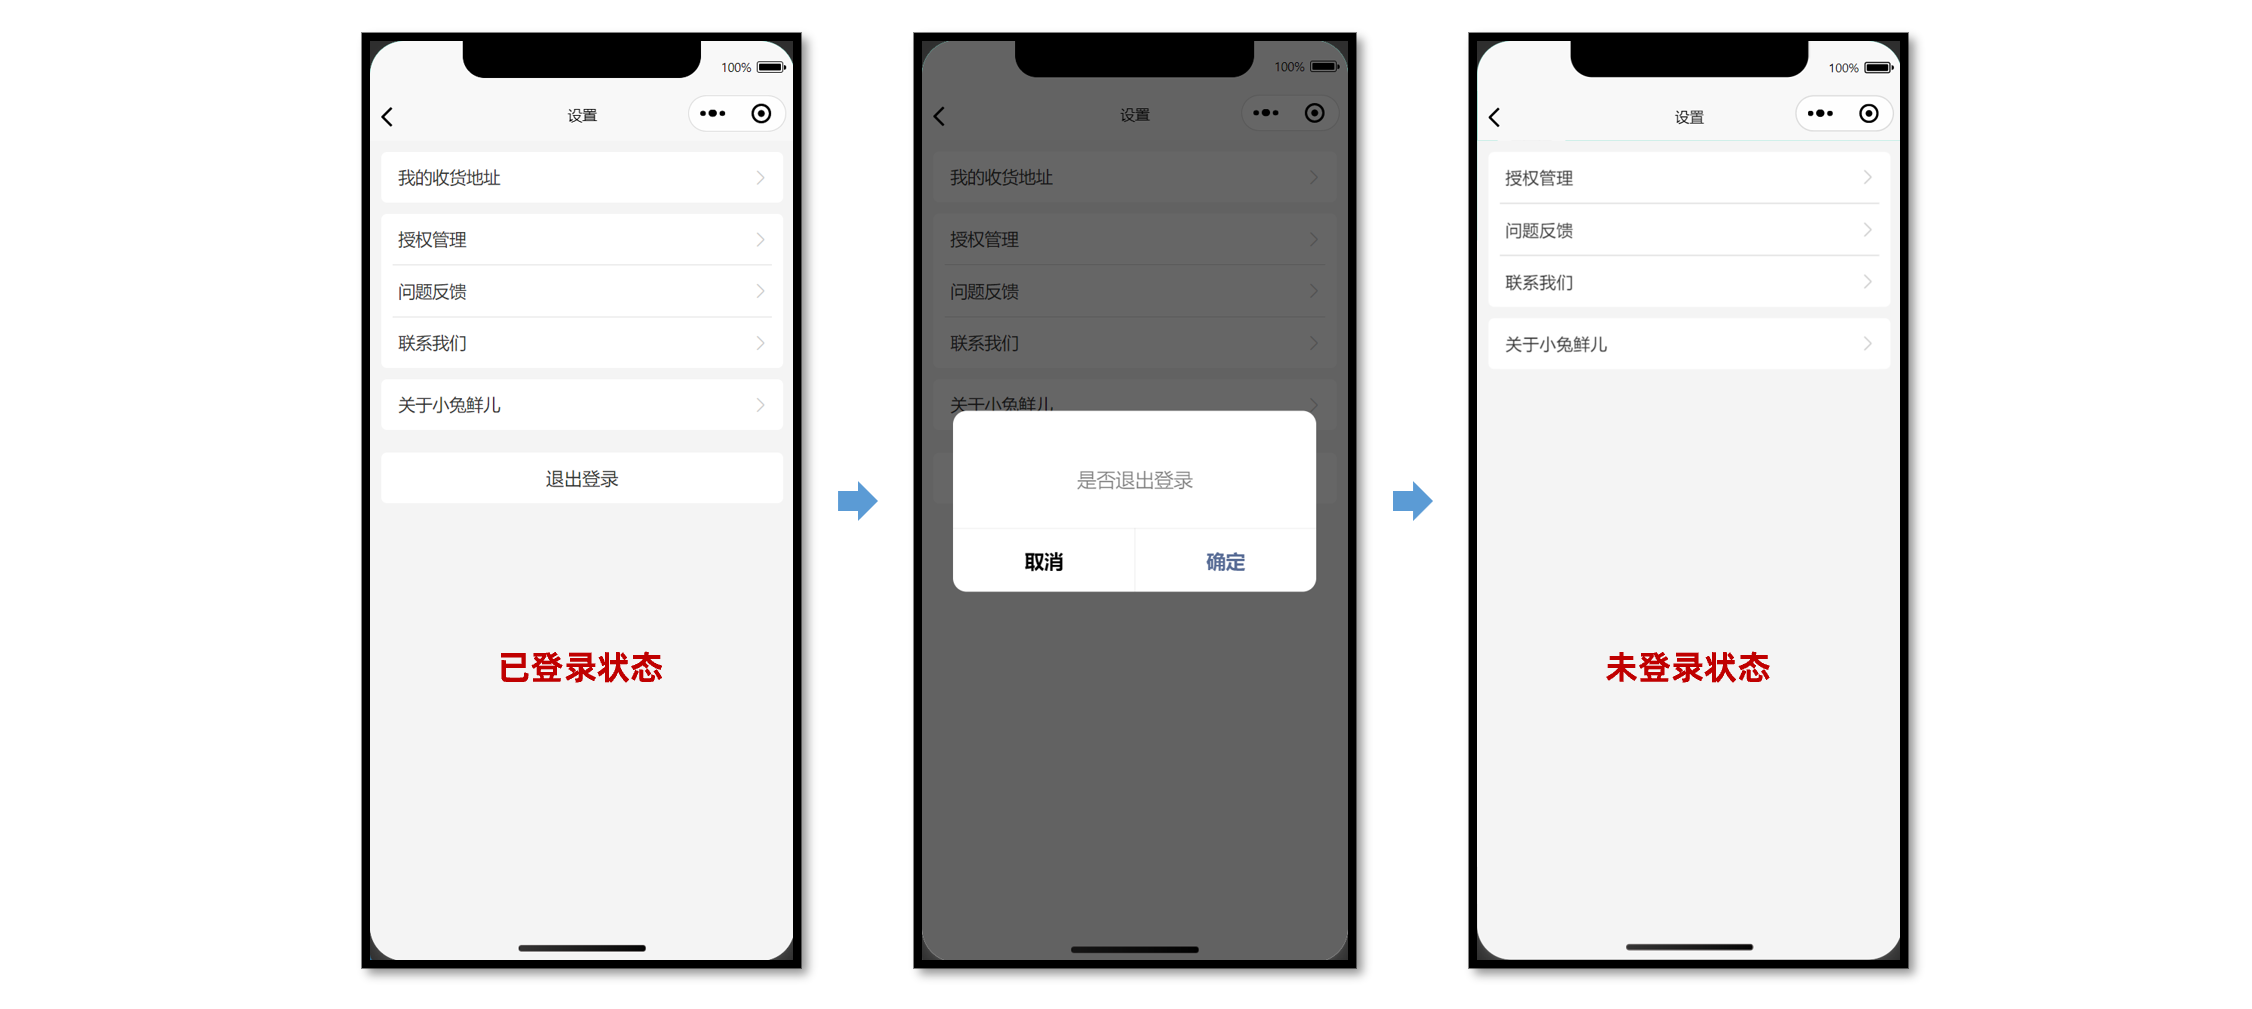


原课设置页的动态代码：

> **原稿路径修正**：该片段把地址写成 `./address/address`，与静态页和分包目录不一致。这里统一为 `/pagesMember/address/address`，对应后续地址页。


```vue
<!-- src/pagesMember/settings/settings.vue -->

<script setup lang="ts">
import { useMemberStore } from '@/stores'

const memberStore = useMemberStore()
// 退出登录
const onLogout = () => {
  // 模态弹窗
  uni.showModal({
    content: '是否退出登录？',
    success: (res) => {
      if (res.confirm) {
        // 清理用户信息
        memberStore.clearProfile()
        // 返回上一页
        uni.navigateBack()
      }
    },
  })
}
</script>

<template>
  <view class="viewport">
    <!-- 列表1 -->
    <view class="list" v-if="memberStore.profile">
      <navigator url="/pagesMember/address/address" hover-class="none" class="item arrow">
        我的收货地址
      </navigator>
    </view>
    <!-- 列表2 -->
    <view class="list">
      <button hover-class="none" class="item arrow" open-type="openSetting">授权管理</button>
      <button hover-class="none" class="item arrow" open-type="feedback">问题反馈</button>
      <button hover-class="none" class="item arrow" open-type="contact">联系我们</button>
    </view>
    <!-- 列表3 -->
    <view class="list">
      <navigator hover-class="none" class="item arrow" url=" ">关于小兔鲜儿</navigator>
    </view>
    <!-- 操作按钮 -->
    <view class="action" v-if="memberStore.profile">
      <view @tap="onLogout" class="button">退出登录</view>
    </view>
  </view>
</template>
```

`uni.showModal` 的成功回调不等于用户确认退出，还要判断 `res.confirm`；取消时保持会员状态。

`clearProfile()` 同时影响响应式 Store 与 01 的持久化存储。返回“我的”后，页面根据空会员状态展示登录入口。原课没有额外请求退出接口，处理的是本地会员状态清理。

`v-if="memberStore.profile"` 控制地址列表和退出区域，其余设置项仍显示。


## 会员信息页

用户可以编辑昵称、性别、生日、城市、职业，并上传新头像。涉及资料查询、表单数据收集、图片选择和文件上传。

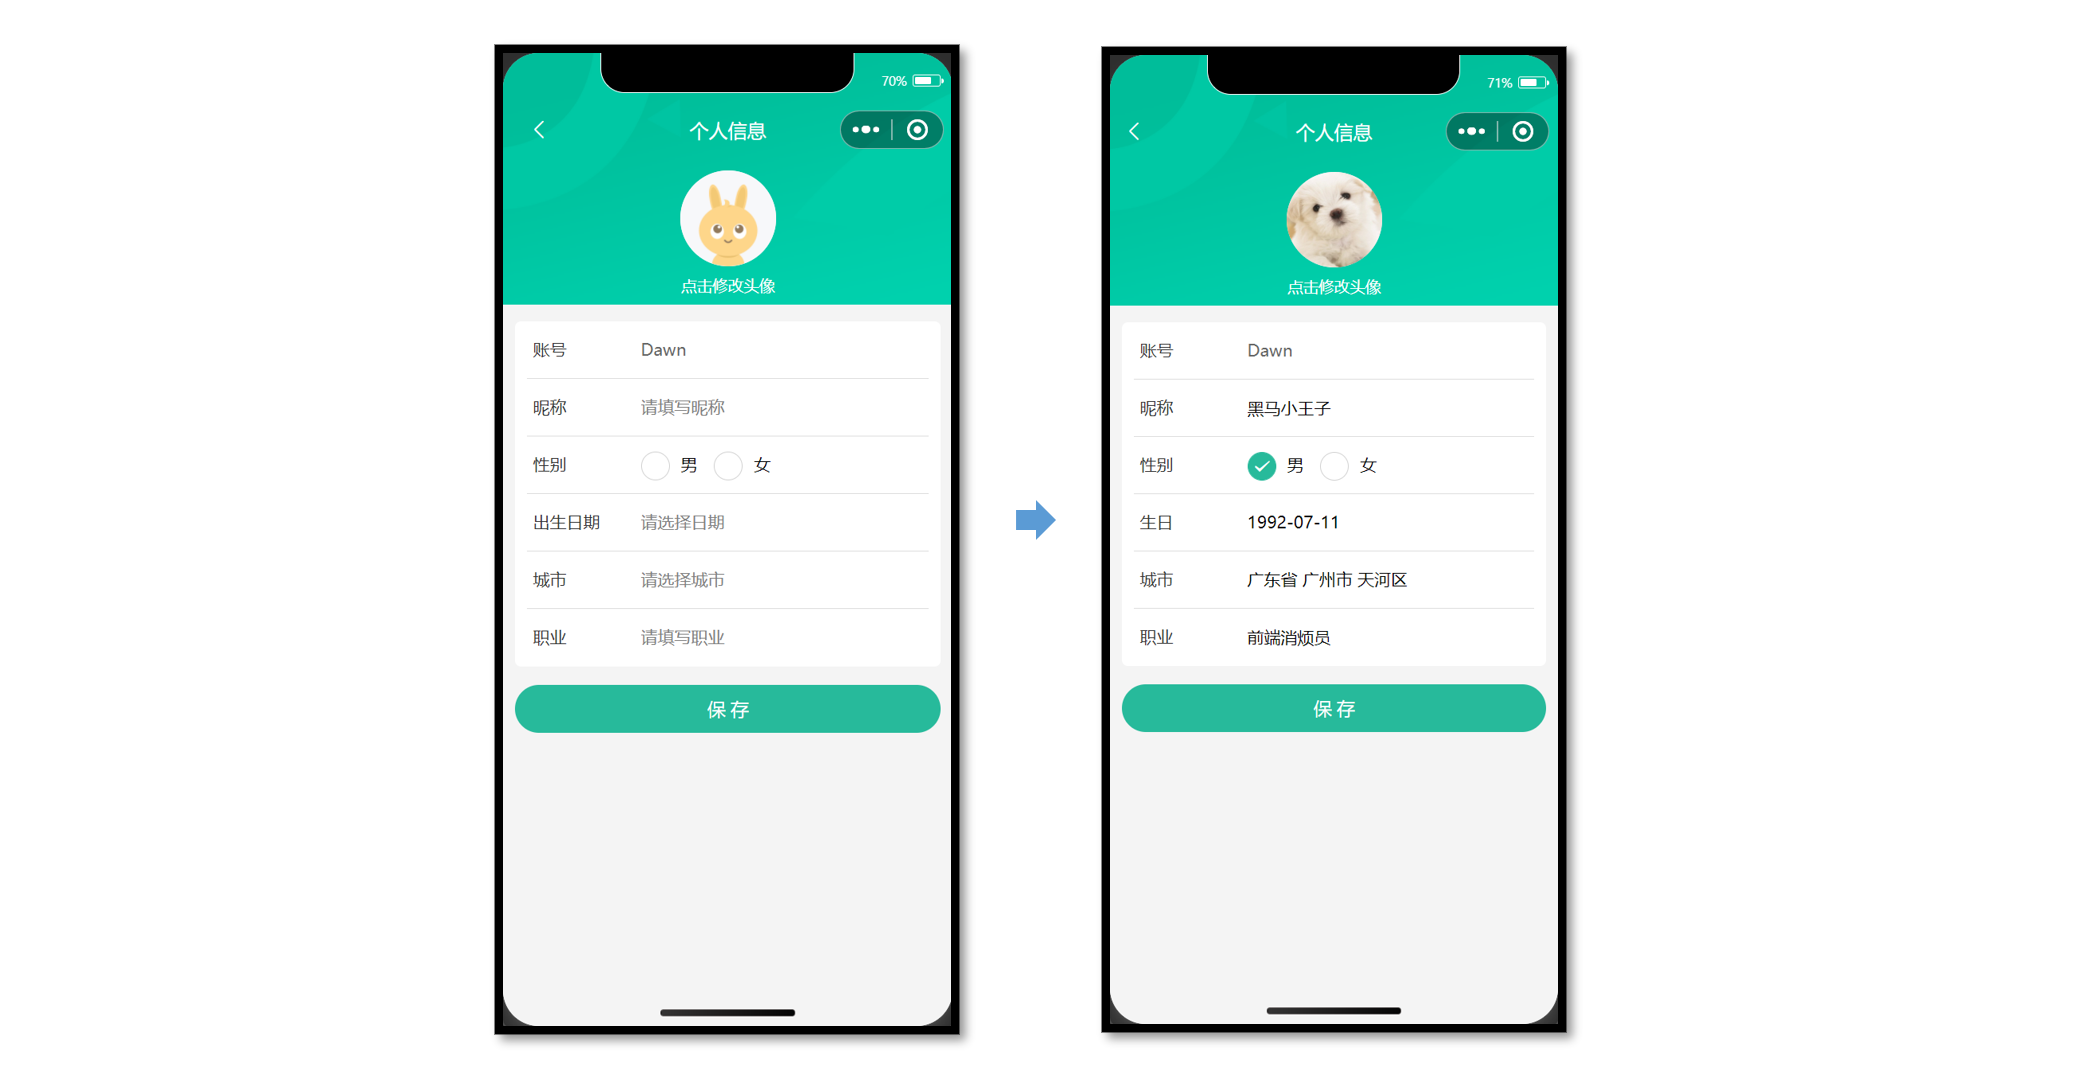


### 创建个人信息页并准备静态结构

新建 `src/pagesMember/profile/profile.vue`，作为会员分包页面。原课使用自定义导航栏，显示返回图标和“个人信息”标题。

在已有 `root: "pagesMember"` 的 `pages` 数组中追加个人信息页，保留设置页。下面是按本页结构补齐的路由配置：


```json
{
  "path": "profile/profile",
  "style": {
    "navigationStyle": "custom",
    "navigationBarTitleText": "个人信息",
    "navigationBarTextStyle": "white"
  }
}
```

然后准备原课完整静态结构和 SCSS：


```vue
<script setup lang="ts">
// 获取屏幕边界到安全区域距离
const { safeAreaInsets } = uni.getSystemInfoSync()
</script>

<template>
  <view class="viewport">
    <!-- 导航栏 -->
    <view class="navbar" :style="{ paddingTop: safeAreaInsets?.top + 'px' }">
      <navigator open-type="navigateBack" class="back icon-left" hover-class="none"></navigator>
      <view class="title">个人信息</view>
    </view>
    <!-- 头像 -->
    <view class="avatar">
      <view class="avatar-content">
        <image class="image" src=" " mode="aspectFill" />
        <text class="text">点击修改头像</text>
      </view>
    </view>
    <!-- 表单 -->
    <view class="form">
      <!-- 表单内容 -->
      <view class="form-content">
        <view class="form-item">
          <text class="label">账号</text>
          <text class="account">账号名</text>
        </view>
        <view class="form-item">
          <text class="label">昵称</text>
          <input class="input" type="text" placeholder="请填写昵称" value="" />
        </view>
        <view class="form-item">
          <text class="label">性别</text>
          <radio-group>
            <label class="radio">
              <radio value="男" color="#27ba9b" :checked="true" />
              男
            </label>
            <label class="radio">
              <radio value="女" color="#27ba9b" :checked="false" />
              女
            </label>
          </radio-group>
        </view>
        <view class="form-item">
          <text class="label">生日</text>
          <picker
            class="picker"
            mode="date"
            start="1900-01-01"
            :end="new Date()"
            value="2000-01-01"
          >
            <view v-if="false">2000-01-01</view>
            <view class="placeholder" v-else>请选择日期</view>
          </picker>
        </view>
        <view class="form-item">
          <text class="label">城市</text>
          <picker class="picker" mode="region" :value="['广东省', '广州市', '天河区']">
            <view v-if="false">广东省广州市天河区</view>
            <view class="placeholder" v-else>请选择城市</view>
          </picker>
        </view>
        <view class="form-item">
          <text class="label">职业</text>
          <input class="input" type="text" placeholder="请填写职业" value="" />
        </view>
      </view>
      <!-- 提交按钮 -->
      <button class="form-button">保 存</button>
    </view>
  </view>
</template>

<style lang="scss">
page {
  background-color: #f4f4f4;
}

.viewport {
  display: flex;
  flex-direction: column;
  height: 100%;
  background-image: url(https://pcapi-xiaotuxian-front-devtest.itheima.net/miniapp/images/order_bg.png);
  background-size: auto 420rpx;
  background-repeat: no-repeat;
}

// 导航栏
.navbar {
  position: relative;

  .title {
    height: 40px;
    display: flex;
    justify-content: center;
    align-items: center;
    font-size: 16px;
    font-weight: 500;
    color: #fff;
  }

  .back {
    position: absolute;
    height: 40px;
    width: 40px;
    left: 0;
    font-size: 20px;
    color: #fff;
    display: flex;
    justify-content: center;
    align-items: center;
  }
}

// 头像
.avatar {
  text-align: center;
  width: 100%;
  height: 260rpx;
  display: flex;
  flex-direction: column;
  justify-content: center;
  align-items: center;

  .image {
    width: 160rpx;
    height: 160rpx;
    border-radius: 50%;
    background-color: #eee;
  }

  .text {
    display: block;
    padding-top: 20rpx;
    line-height: 1;
    font-size: 26rpx;
    color: #fff;
  }
}

// 表单
.form {
  background-color: #f4f4f4;

  &-content {
    margin: 20rpx 20rpx 0;
    padding: 0 20rpx;
    border-radius: 10rpx;
    background-color: #fff;
  }

  &-item {
    display: flex;
    height: 96rpx;
    line-height: 46rpx;
    padding: 25rpx 10rpx;
    background-color: #fff;
    font-size: 28rpx;
    border-bottom: 1rpx solid #ddd;

    &:last-child {
      border: none;
    }

    .label {
      width: 180rpx;
      color: #333;
    }

    .account {
      color: #666;
    }

    .input {
      flex: 1;
      display: block;
      height: 46rpx;
    }

    .radio {
      margin-right: 20rpx;
    }

    .picker {
      flex: 1;
    }
    .placeholder {
      color: #808080;
    }
  }

  &-button {
    height: 80rpx;
    text-align: center;
    line-height: 80rpx;
    margin: 30rpx 20rpx;
    color: #fff;
    border-radius: 80rpx;
    font-size: 30rpx;
    background-color: #27ba9b;
  }
}
</style>
```

账号作为文本展示；昵称和职业使用 input；性别使用 radio-group；日期与地区使用 picker。初始静态数据随后换成查询结果。

合并动态片段时继续使用这段样式。页面导航顶部占位沿用安全区数据。原稿日期 picker 的 `end` 使用 `new Date()`，若当前类型或平台要求日期字符串，应整理为对应的 `YYYY-MM-DD` 格式。


### 查询会员个人信息

`GET /member/profile` 需要登录，无额外请求参数。01 的请求拦截器自动读取 Store 的 Token，这里不用每次重复添加认证请求头。

新建 `src/services/profile.ts`：


```typescript
import type { ProfileDetail } from '@/types/member'
import { http } from '@/utils/http'

/**
 * 获取个人信息
 */
export const getMemberProfileAPI = () => {
  return http<ProfileDetail>({
    method: 'GET',
    url: '/member/profile',
  })
}
```

在 `src/types/member.d.ts` 中追加个人信息类型，保留 06 的 `LoginResult`：


```typescript
/** 个人信息 用户详情信息 */
export type ProfileDetail = {
  /** 用户ID */
  id: number
  /** 头像  */
  avatar: string
  /** 账户名  */
  account: string
  /** 昵称 */
  nickname?: string
  /** 性别 */
  gender?: Gender
  /** 生日 */
  birthday?: string
  /** 省市区 */
  fullLocation?: string
  /** 职业 */
  profession?: string
}
/** 性别 */
export type Gender = '女' | '男'
```

`Gender` 是 `'女' | '男'` 的联合类型。昵称、性别、生日、地区文字和职业均按原稿声明为可选字段，展示与编辑时要考虑尚未填写的情况。

`ProfileDetail` 是个人资料，不包含 Token；登录 Store 仍保存 06 的 `LoginResult`。不能用个人详情响应直接覆盖整份登录信息，否则会丢失 Token 等登录字段。


### 可选：复用会员通用类型

原课提供可选的类型整理方式，在 `src/types/member.d.ts` 中提取共同字段：


```typescript
/** 封装通用信息 */
type BaseProfile = {
  /** 用户ID */
  id: number
  /** 头像  */
  avatar: string
  /** 账户名  */
  account: string
  /** 昵称 */
  nickname?: string
}

/** 小程序登录 登录用户信息 */
export type LoginResult = BaseProfile & {
  /** 用户ID */
  id: number
  /** 头像  */
  avatar: string
  /** 账户名  */
  account: string
  /** 昵称 */
  nickname?: string
  /** 手机号 */
  mobile: string
  /** 登录凭证 */
  token: string
}

/** 个人信息 用户详情信息 */
export type ProfileDetail = BaseProfile & {
  /** 性别 */
  gender?: Gender
  /** 生日 */
  birthday?: string
  /** 省市区 */
  fullLocation?: string
  /** 职业 */
  profession?: string
}
/** 性别 */
export type Gender = '女' | '男'
```

选择这套结构时，替换原有同名的 `LoginResult`、`ProfileDetail`、`Gender` 定义，不能再保留两份声明。

`BaseProfile` 提取 ID、头像、账号和昵称。原稿的 `LoginResult` 又列了一遍这些公共字段，属于冗余描述；理解交叉类型时，核心是共享基础字段后再增加 `mobile` 和 `token`。

这是可选整理，不影响本篇接口流程。


### 渲染查询结果

会员页保存详情并绑定到表单，原课的只读展示阶段代码为：


```vue
<script setup lang="ts">
import { getMemberProfileAPI } from '@/services/profile'
import type { ProfileDetail } from '@/types/member'
import { onLoad } from '@dcloudio/uni-app'
import { ref } from 'vue'

// 获取屏幕边界到安全区域距离
const { safeAreaInsets } = uni.getSystemInfoSync()

// 获取个人信息
const profile = ref<ProfileDetail>()
const getMemberProfileData = async () => {
  const res = await getMemberProfileAPI()
  profile.value = res.result
}

onLoad(() => {
  getMemberProfileData()
})
</script>

<template>
  <view class="viewport">
    <!-- 导航栏 -->
    <view class="navbar" :style="{ paddingTop: safeAreaInsets?.top + 'px' }">
      <navigator open-type="navigateBack" class="back icon-left" hover-class="none"></navigator>
      <view class="title">个人信息</view>
    </view>
    <!-- 头像 -->
    <view class="avatar">
      <view class="avatar-content">
        <image class="image" :src="profile?.avatar" mode="aspectFill" />
        <text class="text">点击修改头像</text>
      </view>
    </view>
    <!-- 表单 -->
    <view class="form">
      <!-- 表单内容 -->
      <view class="form-content">
        <view class="form-item">
          <text class="label">账号</text>
          <text class="account">{{ profile?.account }}</text>
        </view>
        <view class="form-item">
          <text class="label">昵称</text>
          <input class="input" type="text" placeholder="请填写昵称" :value="profile?.nickname" />
        </view>
        <view class="form-item">
          <text class="label">性别</text>
          <radio-group>
            <label class="radio">
              <radio value="男" color="#27ba9b" :checked="profile?.gender === '男'" />
              男
            </label>
            <label class="radio">
              <radio value="女" color="#27ba9b" :checked="profile?.gender === '女'" />
              女
            </label>
          </radio-group>
        </view>
        <view class="form-item">
          <text class="label">出生日期</text>
          <picker
            class="picker"
            mode="date"
            :value="profile?.birthday"
            start="1900-01-01"
            :end="new Date()"
          >
            <view v-if="profile?.birthday">{{ profile?.birthday }}</view>
            <view class="placeholder" v-else>请选择日期</view>
          </picker>
        </view>
        <view class="form-item">
          <text class="label">城市</text>
          <picker class="picker" :value="profile?.fullLocation?.split(' ')" mode="region">
            <view v-if="profile?.fullLocation">{{ profile.fullLocation }}</view>
            <view class="placeholder" v-else>请选择城市</view>
          </picker>
        </view>
        <view class="form-item">
          <text class="label">职业</text>
          <input class="input" type="text" placeholder="请填写职业" :value="profile?.profession" />
        </view>
      </view>
      <!-- 提交按钮 -->
      <button class="form-button">保 存</button>
    </view>
  </view>
</template>
```

`onLoad` 请求资料，`profile.value = res.result` 保存结果。初始 `profile` 未定义，所以模板使用可选链。

昵称、职业此时只绑定 `:value`，并没有把输入的新值写回状态；性别、日期和地区也只是显示当前值。下面的表单更新步骤再增加 v-model 和 change 事件。


### 更新会员头像

原课步骤：`uni.chooseMedia` 读取一张相册图片或拍照 → 取得临时文件路径 → `uni.uploadFile` 上传 → 用返回的头像 URL 更新页面与 Store。

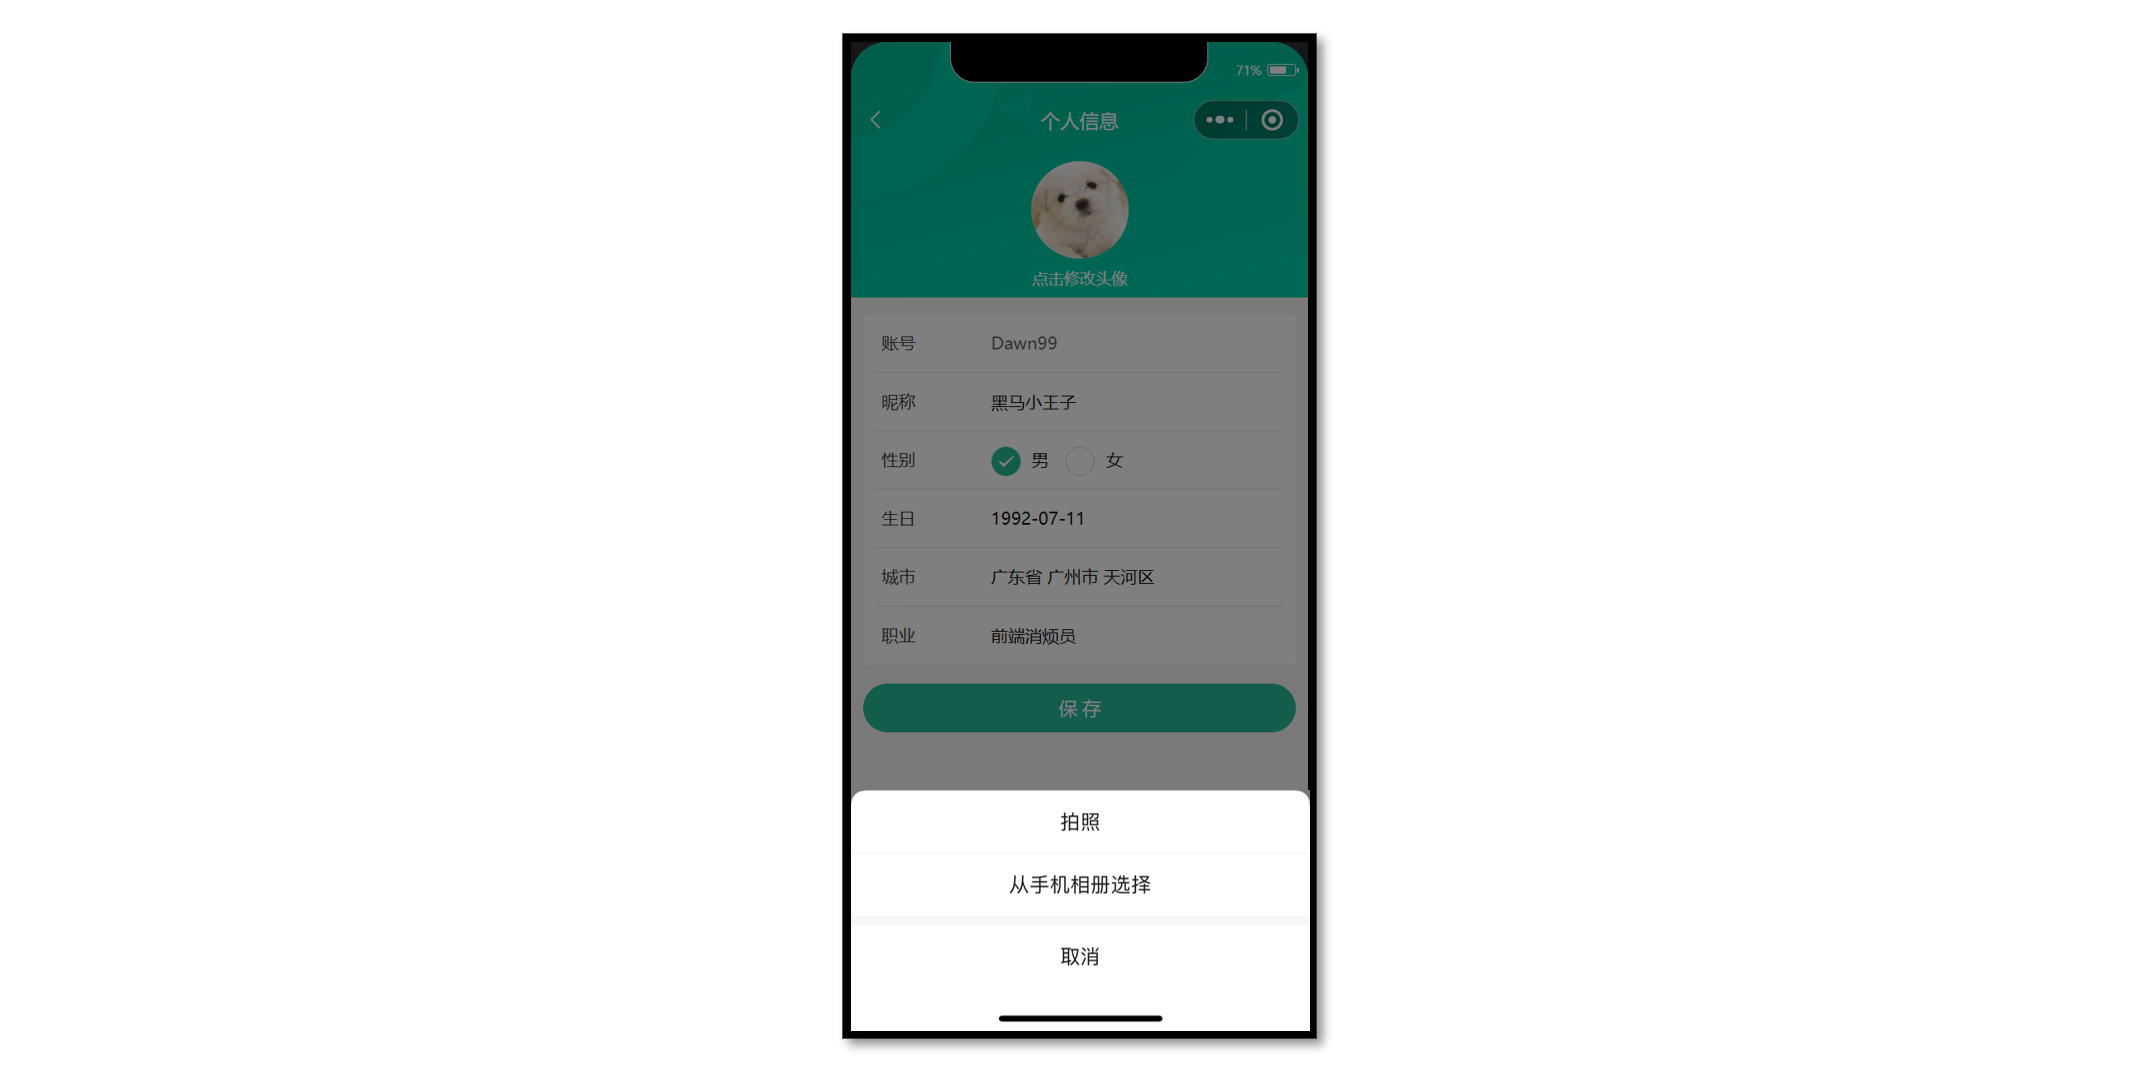


头像上传接口为 `POST /member/profile/avatar`，需要登录。这里的 `name` 与 `filePath` 是 `uni.uploadFile` 的选项：

| 上传选项 | 取值与作用 |
| --- | --- |
| `name` | 固定为 `'file'`，对应服务端接收文件的字段名 |
| `filePath` | 本地图片的临时路径 |
| `url` | `/member/profile/avatar`，由 01 的上传拦截器补基础地址 |

这是文件上传，不是把 `filePath` 当作普通 JSON 字段提交。原课的处理片段：


```vue
<script setup lang="ts">
// ...省略

// 修改头像
const onAvatarChange = () => {
  // 调用拍照/选择图片
  uni.chooseMedia({
    // 文件个数
    count: 1,
    // 文件类型
    mediaType: ['image'],
    success: (res) => {
      // 本地路径
      const { tempFilePath } = res.tempFiles[0]
      // 文件上传
      uni.uploadFile({
        url: '/member/profile/avatar',
        name: 'file', // 后端数据字段名
        filePath: tempFilePath, // 新头像
        success: (res) => {
          // 判断状态码是否上传成功
          if (res.statusCode === 200) {
            // 提取头像
            const { avatar } = JSON.parse(res.data).result
            // 当前页面更新头像
            profile.value!.avatar = avatar
            // 更新 Store 头像
            memberStore.profile!.avatar = avatar
            uni.showToast({ icon: 'success', title: '更新成功' })
          } else {
            uni.showToast({ icon: 'error', title: '出现错误' })
          }
        },
      })
    },
  })
}
</script>
```

此片段沿用会员页已有的 `profile`。`memberStore` 通过 `useMemberStore()` 取得，在同一个脚本内只创建一份，最后的保存片段也会使用它。

原稿没有重新列出头像点击模板，可按方法名补齐到已有头像容器：


```vue
<view class="avatar-content" @tap="onAvatarChange">
  <image class="image" :src="profile?.avatar" mode="aspectFill" />
  <text class="text">点击修改头像</text>
</view>
```

`count: 1` 与 `mediaType: ['image']` 限定一张图片。上传回调的 `res.data` 是字符串，需要 `JSON.parse` 后读取 `result.avatar`，不能按普通请求对象直接访问。

成功后更新两处：当前页 `profile.avatar` 与 Store 的 `memberStore.profile.avatar`。Store 更新后，“我的”页面的头像和持久化内容也会跟着变化。

**原课知识回顾**：网页上传常用 Axios + FormData，小程序原生上传使用 [wx.uploadFile](https://developers.weixin.qq.com/miniprogram/dev/api/network/upload/wx.uploadFile.html)，uni-app 通过 [uni.uploadFile](https://uniapp.dcloud.net.cn/api/request/network-file.html#uploadfile) 提供对应的跨端接口。微信端还需在[公众平台](https://mp.weixin.qq.com/)配置上传合法域名。


头像流程的当前边界：

- `uni.chooseMedia` 的支持范围按当前运行平台确认，不能只因上传 API 跨端，就假定选图 API 在所有端相同。
- 原课依赖选择成功后的 `tempFiles[0]`，上传成功条件写为 HTTP `200`；取消选图、网络失败等分支没有在这段代码中展开。
- 01 的 `uploadFile` 拦截器负责基础地址、Header 和 Token。它不等于 `http<T>` 的响应封装，因此此处自己解析上传响应；上传 401 也不会自动经过普通请求函数的 401 分支。
- `profile.value!` 和 `memberStore.profile!` 是类型断言，前提是页面资料与登录信息存在，不能替代运行时判断。

**跟做检查**：上传后头像 URL 应来自服务器响应；当前个人页、“我的”页面和重新启动后的会员头像应一致。


### 修改个人信息接口

在 `src/services/profile.ts` 中追加 `PUT /member/profile`，需要登录：

| Body 字段 | 原课接口表要求 | 用途 |
| --- | --- | --- |
| `nickname` | 必需 | 昵称 |
| `gender` | 必需 | 性别 |
| `birthday` | 必需 | 生日 |
| `profession` | 必需 | 职业 |

服务文件顶部的类型导入扩展为：


```typescript
import type { ProfileDetail, ProfileParams } from '@/types/member'
```

```typescript
/**
 * 修改个人信息
 * @param data 请求体参数
 */
export const putMemberProfileAPI = (data: ProfileParams) => {
  return http<ProfileDetail>({
    method: 'PUT',
    url: '/member/profile',
    data,
  })
}
```

公共 `http` 导入继续保留。在 `src/types/member.d.ts` 中追加修改参数类型：


```typescript
/** 个人信息 修改请求体参数 */
export type ProfileParams = Pick<
  ProfileDetail,
  'nickname' | 'gender' | 'birthday' | 'profession'
> & {
  /** 省份编码 */
  provinceCode?: string
  /** 城市编码 */
  cityCode?: string
  /** 区/县编码 */
  countyCode?: string
}
```

`Pick` 从详情类型选取四个表单字段，再补充省、市、区编码。它保留原字段的可选性，因此这份类型本身不保证接口表要求的四项都已填写；提交前仍要检查实际表单值。

`fullLocation` 是页面展示文字，后端修改地区使用 `provinceCode`、`cityCode`、`countyCode`。


### 收集昵称、性别和职业

输入框使用 `v-model`，性别使用 `radio-group @change`。原稿用增删高亮表示替换初始状态：

> **原稿整理**：删去带 `[!code --]` 标记的旧 `profile` 定义，只保留 `ref({} as ProfileDetail)`，避免同一脚本重复声明。下面补齐局部片段省略的 `ref` 导入。


```vue
<script setup lang="ts">
import type { Gender, ProfileDetail } from '@/types/member'
import { ref } from 'vue'

// 获取个人信息，修改个人信息需提供初始值
const profile = ref({} as ProfileDetail)

// 修改性别
const onGenderChange: UniHelper.RadioGroupOnChange = (ev) => {
  profile.value.gender = ev.detail.value as Gender
}
</script>

<template>
  <view class="viewport">
    <!-- 表单 -->
    <view class="form">
      <!-- 表单内容 -->
      <view class="form-content">
        <view class="form-item">
          <text class="label">账号</text>
          <text class="account">{{ profile.account }}</text>
        </view>
        <view class="form-item">
          <text class="label">昵称</text>
          <input class="input" type="text" placeholder="请填写昵称" v-model="profile.nickname" />
        </view>
        <view class="form-item">
          <text class="label">性别</text>
          <radio-group @change="onGenderChange">
            <label class="radio">
              <radio value="男" color="#27ba9b" :checked="profile.gender === '男'" />
              男
            </label>
            <label class="radio">
              <radio value="女" color="#27ba9b" :checked="profile.gender === '女'" />
              女
            </label>
          </radio-group>
        </view>
        ...省略
        <view class="form-item">
          <text class="label">职业</text>
          <input class="input" type="text" placeholder="请填写职业" v-model="profile.profession" />
        </view>
      </view>
    </view>
  </view>
</template>
```

原课用空对象作为可编辑状态初值，减少模板对 undefined 的访问。`as ProfileDetail` 不会自动补齐 ID、头像等字段；仍然需要先请求资料，再允许编辑与提交。

查询资料的函数保留，取得数据后替换为真实详情。昵称、职业由 v-model 写回；性别事件把选项值写入 `profile.value.gender`，`as Gender` 也是类型提示，不是运行时转换。


### 收集生日与地区

picker 使用 change 事件：


```vue
<script setup lang="ts">
// 修改生日
const onBirthdayChange: UniHelper.DatePickerOnChange = (ev) => {
  profile.value.birthday = ev.detail.value
}

// 修改城市
let fullLocationCode: [string, string, string] = ['', '', '']
const onFullLocationChange: UniHelper.RegionPickerOnChange = (ev) => {
  // 修改前端界面
  profile.value.fullLocation = ev.detail.value.join(' ')
  // 提交后端更新
  fullLocationCode = ev.detail.code!
}
</script>

<template>
  <view class="form-item">
    <text class="label">生日</text>
    <picker
      class="picker"
      mode="date"
      start="1900-01-01"
      :end="new Date()"
      :value="profile.birthday"
      @change="onBirthdayChange"
    >
      <view v-if="profile.birthday">{{ profile.birthday }}</view>
      <view class="placeholder" v-else>请选择日期</view>
    </picker>
  </view>
  <view class="form-item">
    <text class="label">城市</text>
    <picker
      class="picker"
      mode="region"
      :value="profile.fullLocation?.split(' ')"
      @change="onFullLocationChange"
    >
      <view v-if="profile.fullLocation">{{ profile.fullLocation }}</view>
      <view class="placeholder" v-else>请选择城市</view>
    </picker>
  </view>
</template>
```

日期值直接写入 `birthday`。地区事件的数据分为两部分：

| 事件数据 | 保存方式 |
| --- | --- |
| `ev.detail.value` | 省、市、区名称数组，join 成页面展示文字 |
| `ev.detail.code` | 省、市、区编码数组，保存到 `fullLocationCode` |

`fullLocationCode` 用三项元组记录编码；原稿使用非空断言读取 `code`，需要确认当前平台的地区事件确实提供该字段。

原课初始编码为三个空字符串，只有选择城市后才更新。如果用户不修改城市就保存，下一段会发送空编码；实际跟做时应按接口约定保留原地区，或仅在重新选择后提交新的编码。


### 保存表单并同步 Store 昵称

原稿的提交片段省略了服务函数导入，这里补齐：


```vue
<script setup lang="ts">
import { useMemberStore } from '@/stores'
import { putMemberProfileAPI } from '@/services/profile'

// 点击保存提交表单
const memberStore = useMemberStore()

// 点击保存提交表单
const onSubmit = async () => {
  const { nickname, gender, birthday, profession } = profile.value
  const res = await putMemberProfileAPI({
    nickname,
    gender,
    birthday,
    profession,
    provinceCode: fullLocationCode[0],
    cityCode: fullLocationCode[1],
    countyCode: fullLocationCode[2],
  })
  // 更新Store昵称
  memberStore.profile!.nickname = res.result.nickname
  uni.showToast({ icon: 'success', title: '保存成功' })
  setTimeout(() => {
    uni.navigateBack()
  }, 400)
}
</script>

<template>
  <!-- 提交按钮 -->
  <button @tap="onSubmit" class="form-button">保 存</button>
</template>
```

`onSubmit` 提取可编辑字段和地区编码，调用 PUT 接口。成功后用响应中的昵称更新 Store，而不是只改当前页，确保返回“我的”能显示新昵称。

保存成功提示后等待 `400` 毫秒，`uni.navigateBack` 返回前一页。头像在独立上传流程中即时更新，表单保存负责其余资料和昵称同步。

合并会员页脚本时，保留一份 `profile`、一份 `memberStore`，并合并 `getMemberProfileAPI`、`putMemberProfileAPI` 的导入；头像上传与保存共用同一个 Store 实例。


## 本篇完成检查

- [ ] “我的”按 Store 显示头像、昵称或登录入口，昵称为空时显示账号。
- [ ] 猜你喜欢的组合式函数导入完整，触底能加载下一页。
- [ ] 会员页面已注册在 `pagesMember`，进入“我的”触发分包预下载。
- [ ] 退出弹窗确认后清理会员状态，取消时保持登录。
- [ ] 个人信息查询使用已登录 Token，表单能显示接口数据。
- [ ] 修改头像后，当前页面与 Store 都使用上传返回的 URL。
- [ ] 昵称、职业、性别、生日与城市事件都能写回编辑状态。
- [ ] 表单中只保留一个 `profile` 定义，服务与 Store 导入完整。
- [ ] 保存前检查必填值与地区编码；成功后 Store 昵称更新。
- [ ] 静态页面的完整 SCSS 在动态改造后仍保留。

本篇完成会员展示、退出和资料更新；收货地址及订单页面按后续模块继续实现。
